**NOTE (oldest file in this folder, likely superseded):** an early, first exploration of drift correction — uses SpikeInterface's own built-in `spikeinterface.preprocessing.correct_motion` directly, which is neither the interpolation approach in `peak_localisation.py` nor the direct-subtraction approach `correct_motion.py` (this folder's actual name) settled on. Predates both by months; check before relying on anything here.

In [1]:
######## Import LIBRARY ########
import os
import spikeinterface.full as si 
import spikeinterface.widgets as sw
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from spikeinterface.preprocessing import correct_motion, scale, load_motion_info, whiten, compute_motion, get_motion_presets, get_motion_parameters_preset
from spikeinterface.widgets import plot_motion, plot_motion_info
from spikeinterface.sortingcomponents.motion import interpolate_motion

In [2]:
ks_params = si.get_default_sorter_params('kilosort4')
print(ks_params)

{'batch_size': 60000, 'nblocks': 1, 'Th_universal': 9, 'Th_learned': 8, 'nt': 61, 'shift': None, 'scale': None, 'artifact_threshold': inf, 'nskip': 25, 'whitening_range': 32, 'highpass_cutoff': 300, 'binning_depth': 5, 'sig_interp': 20, 'drift_smoothing': [0.5, 0.5, 0.5], 'nt0min': None, 'dmin': None, 'dminx': 32, 'min_template_size': 10, 'template_sizes': 5, 'nearest_chans': 10, 'nearest_templates': 100, 'max_channel_distance': 32, 'max_peels': 100, 'templates_from_data': True, 'n_templates': 6, 'n_pcs': 6, 'Th_single_ch': 6, 'acg_threshold': 0.2, 'ccg_threshold': 0.25, 'cluster_neighbors': 10, 'cluster_downsampling': 1, 'max_cluster_subset': 25000, 'x_centers': None, 'duplicate_spike_ms': 0.25, 'position_limit': 100, 'do_CAR': True, 'invert_sign': False, 'save_extra_vars': False, 'save_preprocessed_copy': False, 'torch_device': 'auto', 'bad_channels': None, 'clear_cache': False, 'do_correction': True, 'skip_kilosort_preprocessing': False, 'keep_good_only': False, 'use_binary_file': T

## Drift map

In [3]:
def plot_drift_map(recording, bin_s, save_dir=None, vmin_percentile=0, vmax_percentile=100, start_time=None, end_time=None): 
    fs = recording.get_sampling_frequency()
    num_channels = recording.get_num_channels()
    segment = 0
    total_samples = recording.get_num_samples(segment)

    start_sample = int(start_time * fs) if start_time is not None else 0
    end_sample = int(end_time * fs) if end_time is not None else total_samples

    bin_size = int(fs * bin_s)
    num_bins = (end_sample - start_sample) // bin_size
    rms_map = np.zeros((num_channels, num_bins), dtype='float32')
    
    for i in tqdm(range(num_bins)):
        start = start_sample + i * bin_size
        end = min(start + bin_size, end_sample)
        traces = recording.get_traces(segment_index=segment, start_frame=start, end_frame=end)
        rms_map[:, i] = np.sqrt(np.mean(traces**2, axis=0))

    # Normalize
    vmin = np.percentile(rms_map, vmin_percentile)
    vmax = np.percentile(rms_map, vmax_percentile)

    figwidth = 30 / 3600 * ((end_sample - start_sample) / fs)
    plt.figure(figsize=(figwidth, 6))
    plt.imshow(
        rms_map, 
        aspect='auto',
        cmap='gray_r',
        interpolation='none',
        extent=[start_time if start_time else 0, end_time if end_time else total_samples/fs, num_channels, 0], 
        vmin=vmin,
        vmax = vmax
    )
    plt.xlabel('Time (seconds)')
    plt.ylabel('Channel index')
    plt.title('Drift map')

    if save_dir is not None:
        plt.savefig(save_dir, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

## Read data

In [4]:
def read_bin_file(data_path, fs, nchan):
    if "imec0" in data_path: 
        rec = si.read_spikeglx(data_path, stream_name='imec0.ap', load_sync_channel=False) 
        dtype = rec.get_dtype()
        print(dtype)
        rec

    elif "temp_wh.dat" in data_path: 
        rec = si.read_binary(
            file_paths=data_path,
            sampling_frequency=fs,
            num_channels=nchan,
            dtype=np.int16
        )
    
    elif "preprocessed" in data_path: 
        rec = si.load_extractor(data_path)
    
    fs = rec.get_sampling_frequency()
    nchan = rec.get_num_channels()
    
    return rec, fs, nchan

## check variance

In [5]:
def check_variance(rec): 
    traces = rec.get_traces(segment_index=0, start_frame = 0, end_frame = 10000)
    var = np.var(traces, axis=0)  
    print(f"{rec} \n data variances:", "min:", np.min(var), "max:", np.max(var), "ratio", np.max(var)/np.min(var), "\n")

## Main Code

In [6]:
######## PARAMETERS ########
### always read the raw data file first 
recording = "GLC6962_g_g0"
base_folder = f"/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/{recording}"
raw_path = f"{base_folder}/{recording}_imec0"
preprocessed_path = f"{base_folder}/preprocessed"

data_folders = []
data_paths = []
for i in range(len(data_folders)):
    data_paths.append(f"{base_folder}/{data_folders[i]}/sorter_output/temp_wh.dat")
print(data_paths)

[]


In [7]:
rec_raw, fs, nchan = read_bin_file(raw_path,fs=None, nchan=None)
rec_raw

int16


SpikeGLXRecordingExtractor: 384 channels - 30.0kHz - 1 segments - 80,418,082 samples 
                            2,680.60s (44.68 minutes) - int16 dtype - 57.52 GiB

In [8]:
### preprocessed data
rec_preprocessed, fs, nchan = read_bin_file(preprocessed_path, fs=None, nchan=None)
rec_preprocessed

/tmp/ipykernel_31468/1507089750.py:17: DeprecationWarning: load_extractor() is deprecated and will be removed in version 0.104.0. Please use load() instead.
  rec = si.load_extractor(data_path)


BinaryFolderRecording: 355 channels - 30000.283521 Hz - 1 segments - 80,418,082 samples 
                       2,680.58s (44.68 minutes) - float16 dtype - 53.18 GiB

In [9]:
### other data? 
recs = []
for i in range(len(data_paths)):
    r, fs, nchan = read_bin_file(data_paths[i], fs = fs, nchan = nchan)
    recs.append(r)
recs

[]

In [10]:
# Check variance across channels 
check_variance(rec_raw)
check_variance(rec_preprocessed)

if len(data_folders) != 0: 
    for i in range(len(recs)): 
        check_variance(recs[i])

SpikeGLXRecordingExtractor: 384 channels - 30.0kHz - 1 segments - 80,418,082 samples 
                            2,680.60s (44.68 minutes) - int16 dtype - 57.52 GiB 
 data variances: min: 4.077419159999491 max: 135.66172399999803 ratio 33.27146871012765 

BinaryFolderRecording: 355 channels - 30000.283521 Hz - 1 segments - 80,418,082 samples 
                       2,680.58s (44.68 minutes) - float16 dtype - 53.18 GiB 
 data variances: min: 0.2152 max: 3.104 ratio 14.42 



In [11]:
traces = rec_raw.get_traces(start_frame = 200*fs, end_frame = 201*fs)
print(traces)

[[-16  11   5 ...  -6 -20 -34]
 [-20  10   2 ...  -7 -17 -35]
 [-17  11   5 ...  -4 -20 -28]
 ...
 [-17  13   3 ...   5 -13 -25]
 [-19  15   4 ...   0 -17 -24]
 [-20  16   7 ...   6 -23 -29]]


100%|██████████| 2680/2680 [02:14<00:00, 19.86it/s]


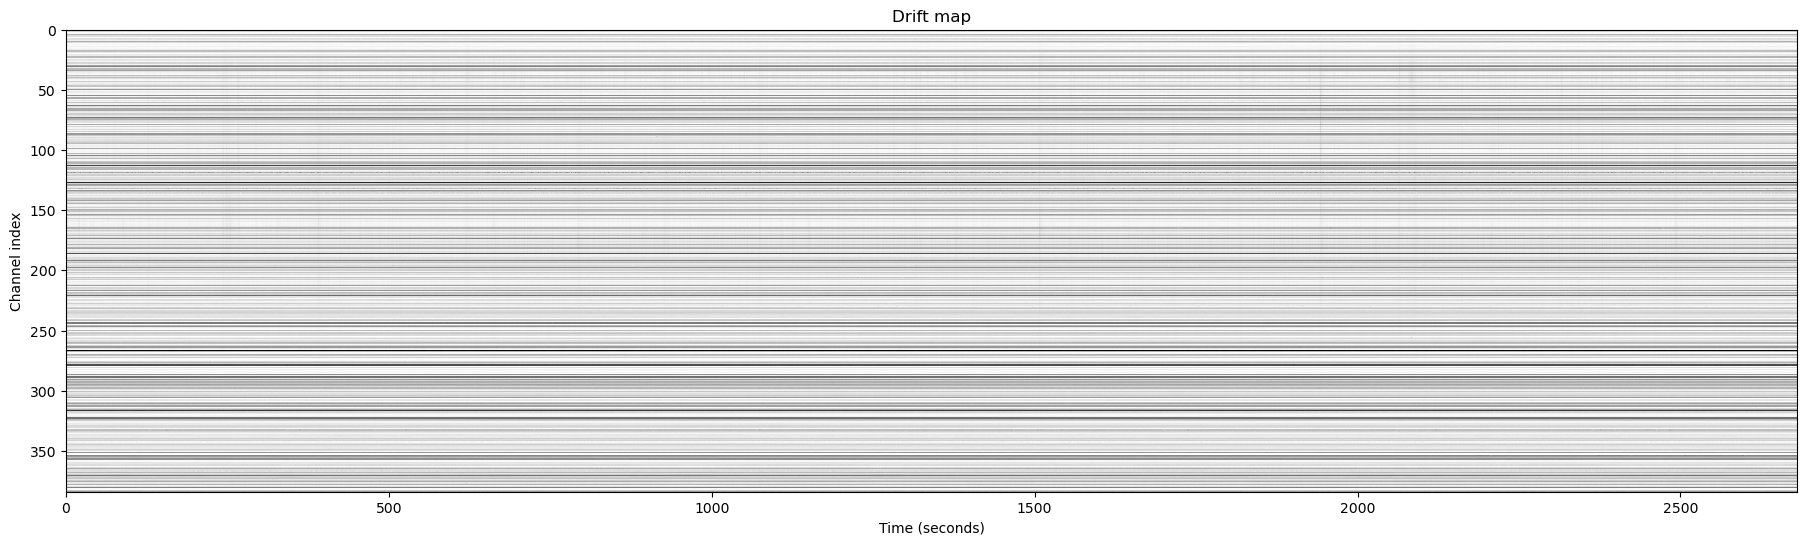

In [12]:
plot_drift_map(rec_raw, bin_s=1, save_dir=os.path.join(base_folder,"raw_drift_map.png"),vmin_percentile=0, vmax_percentile=100, start_time = 0, end_time = None)

100%|██████████| 2680/2680 [06:44<00:00,  6.62it/s]


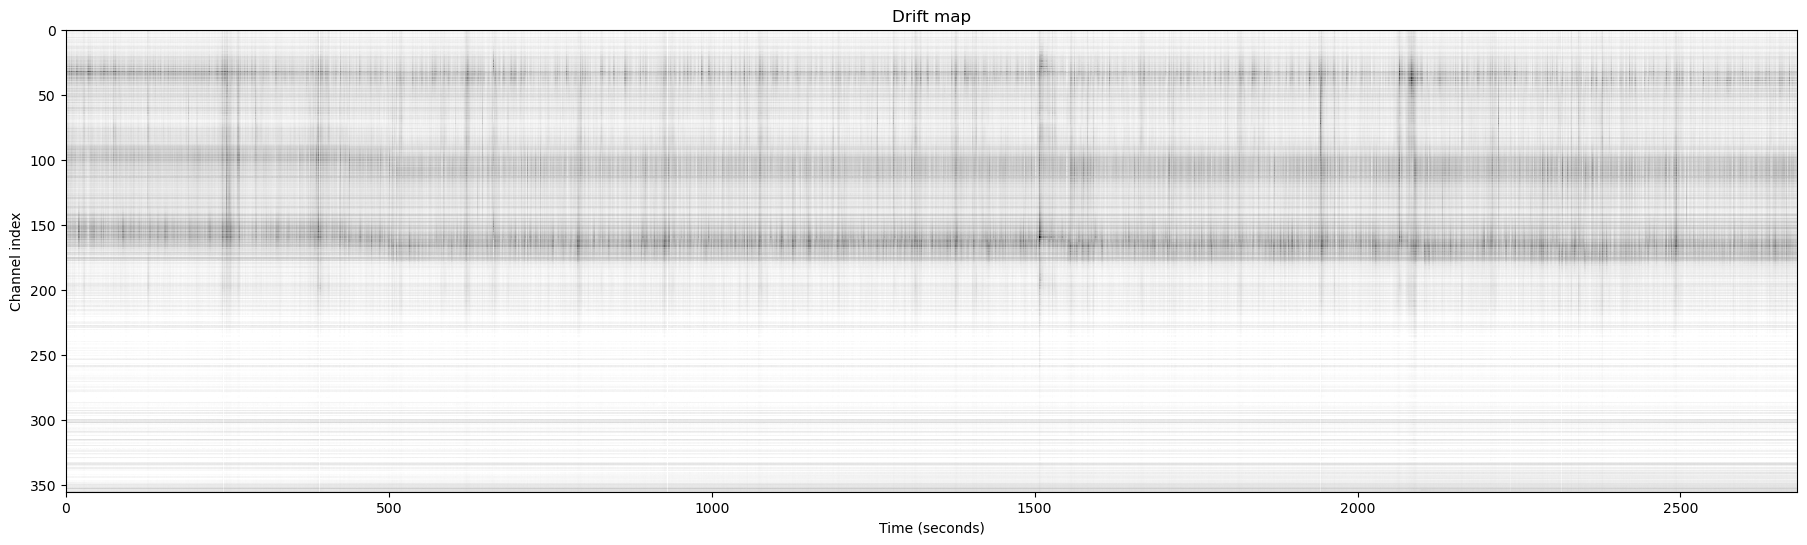

In [13]:
plot_drift_map(rec_preprocessed, bin_s=1, save_dir=os.path.join(base_folder,"preprocessed_drift_map.png"), vmin_percentile=10, vmax_percentile=100, start_time = 0, end_time = None)

In [ ]:
## test drift correction 
correction_mode = "kilosort_like"
motion_folder = os.path.join(base_folder, "motion_correction", correction_mode)
if os.path.exists(motion_folder):
    motion_info = load_motion_info(motion_folder)
    rec_corrected = interpolate_motion(
                  recording=rec.astype('float32'),
                  motion=motion_info['motion']
                  )
else: 
    rec_corrected = correct_motion(rec.astype('float32'), preset = correction_mode,folder=motion_folder) 
    motion_info = load_motion_info(motion_folder)

In [ ]:
######## PARAMETERS ########
base_folder = "/u/gongt/GLC7189_c_g0"
#raw_data_folder = os.path.join(base_folder, "GLC7189_c_g0_t0_imec0")
preprocessed_data_folder2 = os.path.join(base_folder, "kilosort4_nblock1_templateoff_nowhitening","sorter_output", "temp_wh.dat")
preprocessed_data_folder = os.path.join(base_folder, "preprocessed")

rec = si.load_extractor(preprocessed_data_folder)
sampling_frequency = rec.get_sampling_frequency()
num_channels = rec.get_num_channels()

rec_corrected1 = si.read_binary(
    file_paths=preprocessed_data_folder2,
    sampling_frequency=sampling_frequency,
    num_channels=num_channels,
    dtype=dtype
)

In [ ]:
plot_drift_map(rec_corrected, bin_s=1, save_dir=os.path.join(base_folder,"ks4_drift_map_nowhitening_vmin1.png"), vmin_percentile=1)

In [ ]:
n_samp = rec.get_num_samples()
print(n_samp)

In [ ]:
kilosort_folder = os.path.join(base_folder, "sorting", "kilosort4_nblock1_templateoff","sorter_output")
ops = np.load(os.path.join(kilosort_folder, 'ops.npy'), allow_pickle=True).item()
ops['dshift']

In [17]:
dredge_params = get_motion_parameters_preset("dredge")

dredge_params['detect_kwargs']['detect_threshold'] = 6.0
dredge_params['localize_peaks_kwargs']['max_distance_um'] = 50.0
#dredge_params['localize_peaks_kwargs']['radius_um'] = 125.0
#dredge_params['estimate_motion_kwargs']['win_step_um'] = 200.0
#dredge_params['estimate_motion_kwargs']['win_scale_um'] = 200.0
dredge_params['estimate_motion_kwargs']['rigid'] = True
#dredge_params['interpolate_motion_kwargs']['sigma_um'] = 30.0

if 'doc' in dredge_params:
    del dredge_params['doc']
dredge_params


{'detect_kwargs': {'peak_sign': 'neg',
  'detect_threshold': 6.0,
  'exclude_sweep_ms': 0.8,
  'radius_um': 80.0,
  'noise_levels': None,
  'return_output': True,
  'method': 'locally_exclusive'},
 'select_kwargs': {},
 'localize_peaks_kwargs': {'radius_um': 75.0,
  'max_distance_um': 50.0,
  'optimizer': 'minimize_with_log_penality',
  'enforce_decrease': True,
  'feature': 'ptp',
  'method': 'monopolar_triangulation'},
 'estimate_motion_kwargs': {'direction': 'y',
  'rigid': True,
  'win_shape': 'gaussian',
  'win_step_um': 400.0,
  'win_scale_um': 400.0,
  'win_margin_um': None,
  'method': 'dredge_ap'},
 'interpolate_motion_kwargs': {'border_mode': 'force_extrapolate',
  'spatial_interpolation_method': 'kriging',
  'sigma_um': 20.0,
  'p': 2}}

In [18]:
import json 
## test drift correction 
correction_mode = "dredge"
base_folder = "/u/gongt/GLC7189_g_g1"
motion_folder = os.path.join(base_folder, "motion_correction", correction_mode, "test2_0_3600")

preprocessed_data_folder = os.path.join(base_folder, "preprocessed")

sampling_frequency = rec.get_sampling_frequency()
num_channels = rec.get_num_channels()

fs = rec.get_sampling_frequency()
samples_to_keep = int(3600 * fs)
rec_trimmed = rec.frame_slice(start_frame=0, end_frame=samples_to_keep)
rec_trimmed

if os.path.exists(motion_folder):
    motion_info = load_motion_info(motion_folder)
    rec_corrected = interpolate_motion(
                  recording=rec_trimmed.astype('float32'),
                  motion=motion_info['motion']
                  )
else: 
    rec_corrected = correct_motion(rec_trimmed.astype('float32'), **dredge_params, folder=motion_folder) 
    motion_info = load_motion_info(motion_folder)

params_path = os.path.join(motion_folder, "dredge_params.json")
with open(params_path, 'w') as f:
    json.dump(params_path, f, indent=2)


noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

detect and localize (no parallelization):   0%|          | 0/3600 [00:00<?, ?it/s]

Cross correlation:   0%|          | 0/1 [00:00<?, ?it/s]

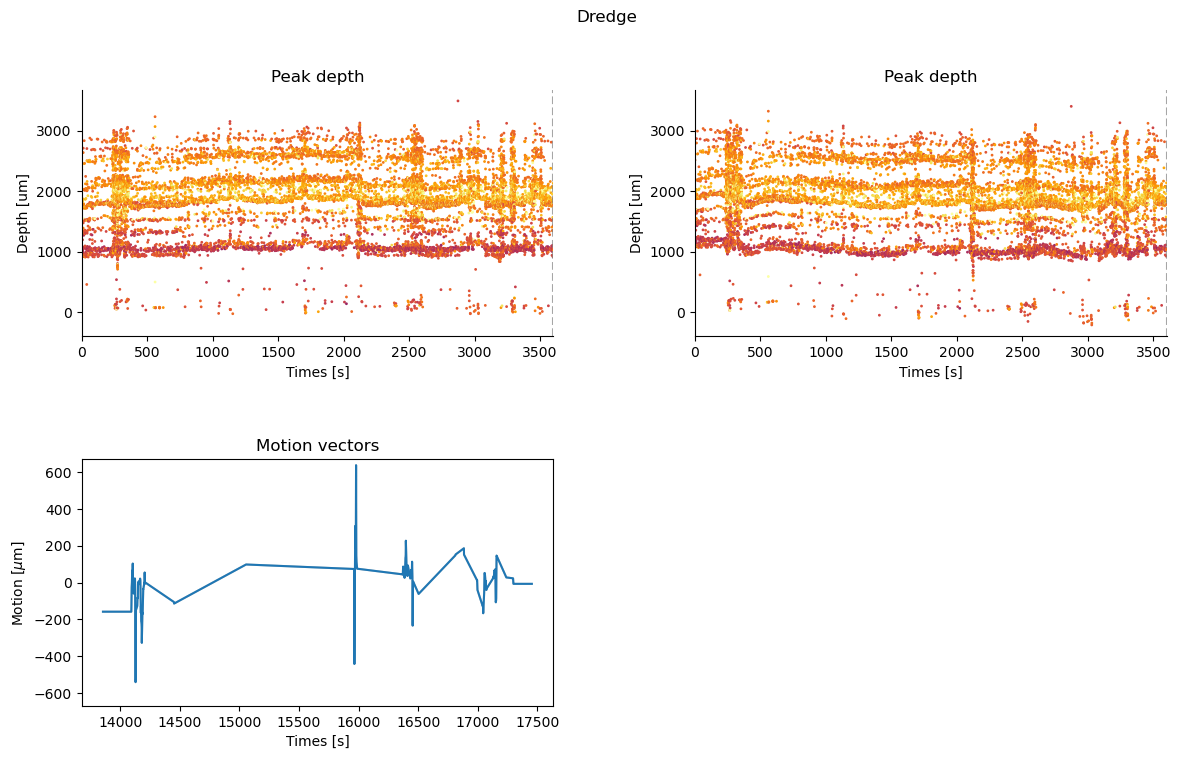

In [19]:
fig = plt.figure(figsize=(14, 8))
si.plot_motion_info(
        motion_info, rec_corrected,
        figure=fig,
        color_amplitude=True,
        amplitude_cmap="inferno",
        scatter_decimate=10,
    )
fig.suptitle("Dredge")
save_path = os.path.join(motion_folder, "summary.png")
fig.savefig(save_path)

100%|██████████| 3600/3600 [13:02<00:00,  4.60it/s]


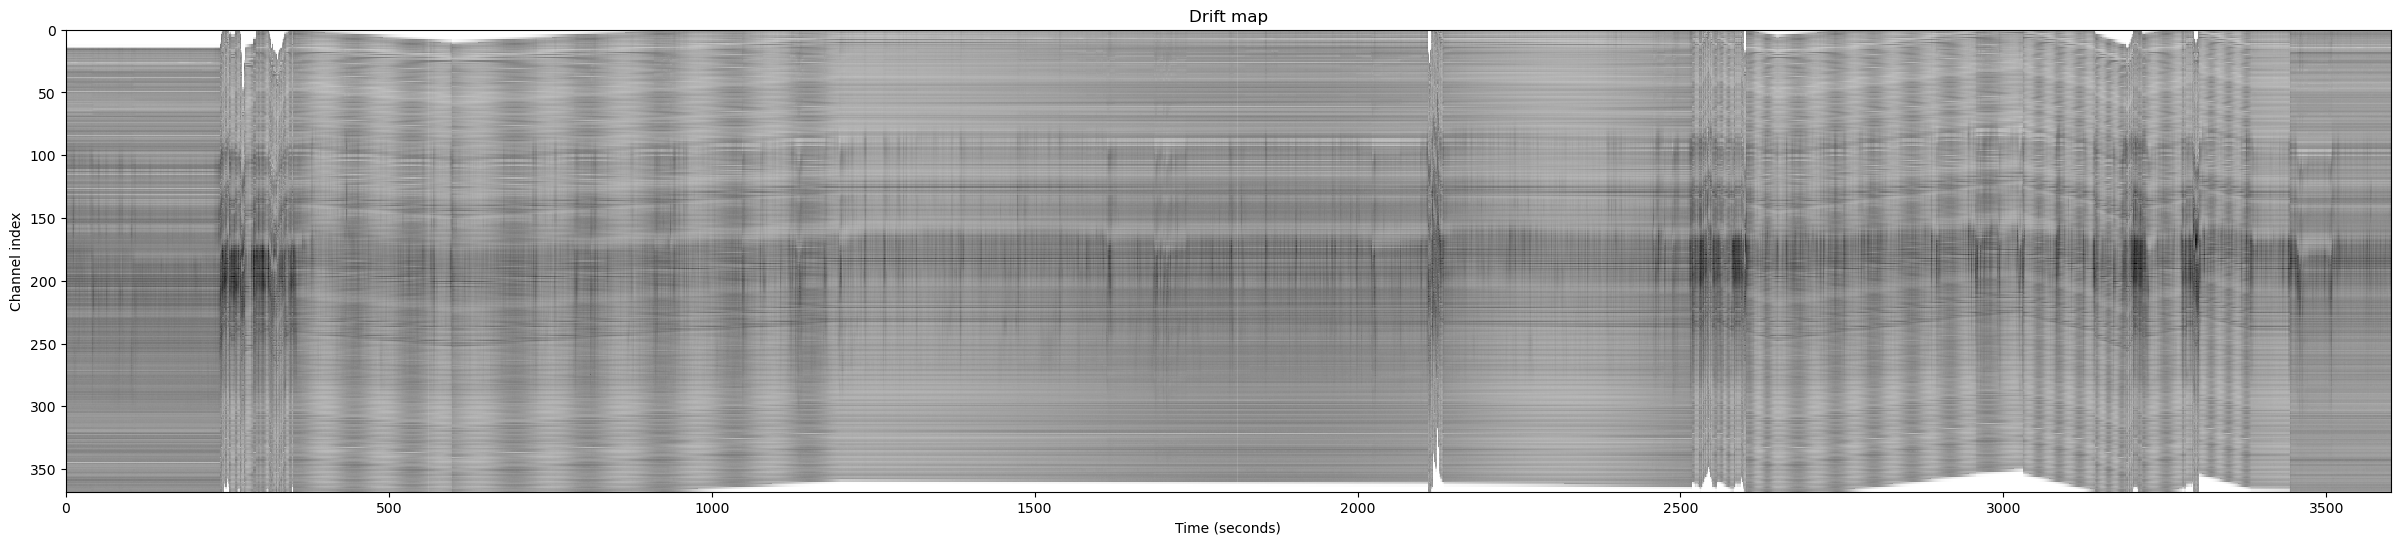

In [20]:
plot_drift_map(rec_corrected, bin_s=1, save_dir=os.path.join(motion_folder,"dredge_drift_map_0_3600.png"), vmin_percentile=1, vmax_percentile=99.9, start_time=0, end_time=3600)